# Partie MLP — Nathan (variante : entropie croisée)

Objectif : entraîner un réseau de neurones (MLP) qui prédit, à chaque date $t$, une allocation entre 15 actions du CAC 40 et le cash, à partir d'indicateurs de marché connus en $t$.
Ce notebook est le **miroir** de `mlp_nathan.ipynb` : tout est identique, sauf que la MSE est remplacée par l'**entropie croisée** pour imiter les poids oracle $Y$. Le modèle Sharpe (étape 4) est inchangé.

## Étape 0 — Mise en place

On importe uniquement des packages standards : pandas pour lire les CSV, scikit-learn pour la normalisation, torch pour le réseau, matplotlib pour les graphiques.
On fixe les **graines aléatoires** de `random`, `numpy` et `torch` : l'initialisation des poids du réseau, le mélange des mini-lots et le dropout sont aléatoires, donc sans graine fixée on obtiendrait un résultat différent à chaque exécution.
Le chemin des données est **relatif** pour que le notebook tourne sur n'importe quel ordinateur.

In [1]:
import copy    # pour copier les meilleurs poids du réseau (early stopping)
import os      # pour créer le dossier outputs
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader  # pour découper les données en mini-lots
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit

# Graines fixées pour la reproductibilité
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = "data/processed/N63_wmax1/"  # relatif à la racine du projet

C:\Users\natha\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\natha\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


## Étape 1 — Chargement et découpage des données

On lit les 4 fichiers. Dans chacun, **une ligne = une date** et la première colonne (la date) sert d'index.
`X` contient les 160 features (entrée du réseau), `Y` les 16 poids oracle (cible de l'entropie croisée), `R_fwd` les rendements réalisés sur les 63 jours suivants (pour la perte Sharpe, jamais en entrée) et `meta` le découpage train / val / test.
On vérifie que les 4 fichiers ont les mêmes dates dans l'ordre chronologique, et que les poids oracle somment bien à 1.

In [2]:
X = pd.read_csv(DATA_DIR + "X.csv", index_col=0, parse_dates=True)
Y = pd.read_csv(DATA_DIR + "Y.csv", index_col=0, parse_dates=True)
R_fwd = pd.read_csv(DATA_DIR + "R_fwd.csv", index_col=0, parse_dates=True)
meta = pd.read_csv(DATA_DIR + "meta.csv", index_col=0, parse_dates=True)

print("X :", X.shape, "| Y :", Y.shape, "| R_fwd :", R_fwd.shape, "| meta :", meta.shape)
print("Mêmes dates dans les 4 fichiers :", X.index.equals(Y.index) and X.index.equals(R_fwd.index) and X.index.equals(meta.index))
print("Dates dans l'ordre chronologique :", X.index.is_monotonic_increasing)
print("Mêmes colonnes dans Y et R_fwd :", list(Y.columns) == list(R_fwd.columns))
print("Somme des poids oracle : min =", Y.sum(axis=1).min().round(4), "| max =", Y.sum(axis=1).max().round(4))

X : (5082, 160) | Y : (5082, 16) | R_fwd : (5082, 16) | meta : (5082, 3)
Mêmes dates dans les 4 fichiers : True
Dates dans l'ordre chronologique : True
Mêmes colonnes dans Y et R_fwd : True
Somme des poids oracle : min = 1.0 | max = 1.0


On découpe avec la colonne `split` de `meta` : le découpage est **chronologique** (train ≈ 2006–2016, val ≈ 2017–2019, test = 2020–2025), car en finance on ne doit jamais apprendre sur le futur pour prédire le passé. Les lignes `none` sont ignorées.
Entre deux ensembles il y a un trou de 63 jours (**purging**) : le label d'une date $t$ utilise les rendements jusqu'à $t+63$, donc sans ce trou les derniers labels du train « verraient » la période de validation. On le vérifie avec la colonne `label_end`.
Le **test** est mis de côté : il ne servira qu'une seule fois, à l'étape 6.

In [3]:
train = meta["split"] == "train"  # Série de True / False, une valeur par date
val = meta["split"] == "val"
test = meta["split"] == "test"

X_train, Y_train, R_train = X[train], Y[train], R_fwd[train]
X_val, Y_val, R_val = X[val], Y[val], R_fwd[val]
X_test = X[test]  # pour le test, on n'a besoin que des entrées (prédictions à l'étape 6)

print("train :", len(X_train), "dates, du", X_train.index[0].date(), "au", X_train.index[-1].date())
print("val   :", len(X_val), "dates, du", X_val.index[0].date(), "au", X_val.index[-1].date())
print("test  :", len(X_test), "dates, du", X_test.index[0].date(), "au", X_test.index[-1].date())

# Purging : le dernier label d'un ensemble doit se terminer avant le début de l'ensemble suivant
fin_labels_train = pd.to_datetime(meta.loc[train, "label_end"]).max()
fin_labels_val = pd.to_datetime(meta.loc[val, "label_end"]).max()
print("Fin des labels train :", fin_labels_train.date(), "< début val ?", fin_labels_train < X_val.index[0])
print("Fin des labels val   :", fin_labels_val.date(), "< début test ?", fin_labels_val < X_test.index[0])

train : 2749 dates, du 2006-01-02 au 2016-10-03
val   : 703 dates, du 2017-01-02 au 2019-10-02
test  : 1474 dates, du 2020-01-02 au 2025-09-30
Fin des labels train : 2016-12-30 < début val ? True
Fin des labels val   : 2019-12-31 < début test ? True


Les features ont des échelles très différentes (un momentum vaut quelques %, le VIX vaut 10 à 80). Un réseau de neurones apprend mal dans ce cas : les grosses valeurs dominent.
On **standardise** chaque colonne : $(x - \text{moyenne}) / \text{écart-type}$, pour qu'elle ait une moyenne de 0 et un écart-type de 1.
La moyenne et l'écart-type sont calculés **sur le train uniquement** (`fit`), puis appliqués tels quels au val et au test (`transform`) : sinon on utiliserait de l'information du futur (fuite de données).

In [4]:
scaler = StandardScaler()
scaler.fit(X_train)  # moyenne et écart-type de chaque colonne, calculés sur le train seulement

X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# Train : exactement 0 et 1 par construction. Val : proche mais pas exact (le marché a changé)
print("Train : moyenne =", X_train_s.mean().round(3), "| écart-type =", X_train_s.std().round(3))
print("Val   : moyenne =", X_val_s.mean().round(3), "| écart-type =", X_val_s.std().round(3))

Train : moyenne = -0.0 | écart-type = 1.0
Val   : moyenne = -0.264 | écart-type = 0.87


PyTorch ne travaille pas avec des tableaux pandas mais avec des **tenseurs** (des tableaux de nombres, comme numpy, sur lesquels torch sait calculer les gradients).
La petite fonction `tenseur` fait cette conversion en `float32` (le type utilisé par les poids du réseau) ; on l'écrit une fois car on s'en sert souvent. On garde les rendements `R` du train et du val, qui serviront à la perte Sharpe (étape 4).

In [5]:
def tenseur(tableau):
    return torch.tensor(tableau, dtype=torch.float32)  # tableau de nombres -> tenseur torch

X_train_t = tenseur(X_train_s)
Y_train_t = tenseur(Y_train.values)  # .values : le tableau de nombres, sans les noms de lignes et colonnes
R_train_t = tenseur(R_train.values)

X_val_t = tenseur(X_val_s)
Y_val_t = tenseur(Y_val.values)
R_val_t = tenseur(R_val.values)

X_test_t = tenseur(X_test_s)

print("Train :", X_train_t.shape, Y_train_t.shape, R_train_t.shape)
print("Val   :", X_val_t.shape, Y_val_t.shape, R_val_t.shape)
print("Test  :", X_test_t.shape)

Train : torch.Size([2749, 160]) torch.Size([2749, 16]) torch.Size([2749, 16])
Val   : torch.Size([703, 160]) torch.Size([703, 16]) torch.Size([703, 16])
Test  : torch.Size([1474, 160])


## Étape 2 — Architecture du MLP

Le réseau reçoit les 160 features d'une date et renvoie 16 poids (15 actions + cash) :
`160 → 64 (ReLU, dropout 0,2) → 32 (ReLU, dropout 0,2) → 16 → softmax`.

| Choix | Justification |
|---|---|
| 2 couches cachées, 64 puis 32 neurones | Petit réseau : on a peu de données **indépendantes** (≈ 43 trimestres en train, car des dates proches se ressemblent). Un gros réseau apprendrait le train par cœur. |
| ReLU | Activation standard : $\max(0, x)$. Simple, rapide, et permet au réseau d'apprendre des relations non linéaires. |
| Dropout 0,2 | À l'entraînement, on éteint au hasard 20 % des neurones à chaque passage : le réseau ne peut pas dépendre d'un seul neurone. Régularisation contre l'overfitting. |
| Softmax en sortie | Transforme 16 nombres quelconques en 16 poids **positifs qui somment à 1** : on obtient toujours un portefeuille valide, long-only, cash inclus. |

On écrit une petite fonction `creer_mlp` car on créera plusieurs réseaux (entropie croisée, Sharpe, validation croisée) : cela évite de recopier l'architecture.

In [6]:
n_features = X.shape[1]  # 160 entrées
n_actifs = Y.shape[1]    # 16 sorties (15 actions + CASH)

def creer_mlp(n_entrees, n1=64, n2=32, dropout=0.2):
    torch.manual_seed(SEED)  # même initialisation à chaque création : comparaisons équitables entre modèles
    model = nn.Sequential(
        nn.Linear(n_entrees, n1), nn.ReLU(), nn.Dropout(dropout),  # couche cachée 1
        nn.Linear(n1, n2), nn.ReLU(), nn.Dropout(dropout),         # couche cachée 2
        nn.Linear(n2, n_actifs),                                   # couche de sortie : 16 scores
        nn.Softmax(dim=1),  # transforme les 16 scores de chaque date en poids >= 0 qui somment à 1
    )
    return model

model = creer_mlp(n_features)
print(model)

# Nombre de paramètres à apprendre (poids + biais de toutes les couches)
n_params = 0
for p in model.parameters():
    n_params = n_params + p.numel()
print("Nombre de paramètres :", n_params, "| dates de train :", len(X_train), "| trimestres indépendants ≈", len(X_train) // 63)

Sequential(
  (0): Linear(in_features=160, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=32, out_features=16, bias=True)
  (7): Softmax(dim=1)
)
Nombre de paramètres : 12912 | dates de train : 2749 | trimestres indépendants ≈ 43


**Vérification** : on fait passer 3 dates de validation dans le réseau **non entraîné**. Chaque ligne de sortie doit contenir 16 poids positifs qui somment à 1 (grâce au softmax).
Comme les poids du réseau sont encore aléatoires et petits, la sortie doit être proche de l'équipondéré ($1/16 \approx 0{,}06$ par actif) : le réseau n'a encore rien appris.

In [7]:
model.eval()  # mode évaluation : le dropout est désactivé
with torch.no_grad():  # simple test, pas besoin de calculer de gradients
    poids = model(X_val_t[:3])  # les 3 premières dates de la validation

print(pd.DataFrame(poids.numpy(), index=X_val.index[:3].date, columns=Y.columns).round(3))
print("Somme des poids de chaque date :", poids.sum(dim=1))

            MC.PA  OR.PA  BN.PA  TTE.PA  VIE.PA  SAN.PA  BNP.PA  GLE.PA  \
2017-01-02  0.061   0.07  0.057   0.065   0.053   0.067   0.057   0.053   
2017-01-03  0.061   0.07  0.056   0.065   0.052   0.067   0.057   0.053   
2017-01-04  0.061   0.07  0.056   0.065   0.052   0.067   0.057   0.052   

            AIR.PA  SU.PA  DG.PA  SGO.PA  AI.PA  ORA.PA  CAP.PA   CASH  
2017-01-02   0.053  0.058  0.080   0.080  0.048   0.065   0.059  0.074  
2017-01-03   0.052  0.058  0.080   0.080  0.049   0.066   0.059  0.074  
2017-01-04   0.053  0.058  0.081   0.081  0.049   0.067   0.060  0.073  
Somme des poids de chaque date : tensor([1.0000, 1.0000, 1.0000])


## Étape 3 — Entraînement avec l'entropie croisée

**L'entropie croisée** mesure l'écart entre deux répartitions qui somment à 1 : ici les poids prédits $p$ et les poids oracle $y$. Pour une date :
$$\text{CE} = -\sum_i y_i \times \log(p_i)$$
puis on fait la moyenne sur les dates.
Exemple sur 2 actifs : oracle = (0,8 ; 0,2). Prédiction (0,6 ; 0,4) → CE = −(0,8 × log 0,6 + 0,2 × log 0,4) ≈ 0,59. Prédiction (0,79 ; 0,21) → CE ≈ 0,50, plus bas car plus proche de l'oracle.

**Différence avec la MSE** : à cause du $\log$, l'entropie croisée punit très fort une prédiction **proche de 0 sur un actif où l'oracle met beaucoup** (log 0,01 ≈ −4,6). C'est la perte standard quand on compare des répartitions (comme les probabilités d'une classification). Elle ne descend pas à 0 : son minimum est atteint quand $p = y$.

**Comment le réseau apprend :**
- **Descente de gradient** : pour chaque paramètre, on calcule le *gradient*, c'est-à-dire dans quel sens le bouger pour faire baisser la perte, puis on le bouge d'un petit pas dans ce sens. On répète des milliers de fois.
- **Adam** : la version de la descente de gradient la plus utilisée. Elle garde en mémoire la direction des pas précédents et adapte la taille du pas pour chaque paramètre. Le *taux d'apprentissage* `lr` fixe l'ordre de grandeur des pas : on garde `lr = 0,0001`, comme dans le notebook MSE, pour que la comparaison soit équitable.
- **Mini-lot** : on calcule la perte et on fait un pas tous les 64 dates, plutôt qu'après les 2 749 : plus de pas par époque, donc un apprentissage plus rapide. Les dates sont **mélangées** à l'intérieur du train pour que les lots ne soient pas toujours les mêmes.
- **Époque** : un passage complet sur toutes les dates du train (ici ≈ 43 mini-lots).
- **Early stopping** : après chaque époque on mesure la perte sur la validation. Si elle ne s'améliore plus pendant 20 époques (*patience*), on arrête et on garde les poids de la meilleure époque. Continuer ne ferait qu'apprendre le train par cœur (overfitting).

On écrit **une seule fonction d'entraînement**, `entrainer`, qui servira aussi à l'étape 4 (perte Sharpe) et à l'étape 5 (validation croisée). On lui donne la **fonction de perte** à utiliser : ici `perte_ce`, la formule ci-dessus écrite à la main.

À chaque époque :
1. **Apprentissage** : le `DataLoader` découpe le train en mini-lots de dates mélangées ; pour chaque lot, le réseau propose des poids, on calcule la perte, `backward()` calcule les gradients et Adam fait un petit pas.
2. **Mesure** : on calcule la perte sur tout le train et toute la validation, en mode `eval` (dropout coupé) et sans gradients.
3. **Early stopping** : si la perte de validation est la plus basse vue jusqu'ici, on prend une « photo » des poids ; après 20 époques sans progrès, on s'arrête et on remet les poids de la photo.

In [8]:
LR = 1e-4        # taux d'apprentissage d'Adam (taille des pas), le même que dans le notebook MSE
N_EPOCHS = 200   # nombre maximal d'époques
PATIENCE = 20    # époques sans amélioration de la validation avant d'arrêter
BATCH_CE = 64    # nombre de dates par mini-lot pour l'entropie croisée
EPS = 1e-8       # tout petit nombre ajouté pour ne jamais calculer log(0)

def perte_ce(poids, Y):
    # pour chaque date : -somme des (poids oracle × log(poids prédit)), puis moyenne sur les dates
    return -(Y * torch.log(poids + EPS)).sum(dim=1).mean()

def entrainer(X_tr, cible_tr, X_va, cible_va, fonction_perte, taille_lot, n1=64, n2=32, dropout=0.2):
    model = creer_mlp(X_tr.shape[1], n1, n2, dropout)  # X_tr.shape[1] = nombre de features en entrée
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    lots = DataLoader(TensorDataset(X_tr, cible_tr), batch_size=taille_lot, shuffle=True)  # mini-lots de dates mélangées

    pertes_train = []
    pertes_val = []
    epoques_sans_progres = 0

    for epoque in range(N_EPOCHS):
        # 1) Apprentissage : un pas d'Adam par mini-lot
        model.train()  # dropout activé
        for X_lot, cible_lot in lots:
            perte = fonction_perte(model(X_lot), cible_lot)
            optimizer.zero_grad()  # efface les gradients du lot précédent
            perte.backward()       # calcule dans quel sens bouger chaque paramètre
            optimizer.step()       # Adam fait un petit pas dans ce sens

        # 2) Mesure sur tout le train et toute la validation : réseau complet, sans gradients
        model.eval()
        with torch.no_grad():
            pertes_train.append(fonction_perte(model(X_tr), cible_tr).item())  # .item() : tenseur -> nombre
            perte_val = fonction_perte(model(X_va), cible_va).item()
        pertes_val.append(perte_val)

        # 3) Early stopping
        if perte_val == min(pertes_val):  # meilleure perte de validation vue jusqu'ici
            meilleurs_poids = copy.deepcopy(model.state_dict())  # "photo" des poids actuels
            epoques_sans_progres = 0
        else:
            epoques_sans_progres = epoques_sans_progres + 1
            if epoques_sans_progres == PATIENCE:
                break

    model.load_state_dict(meilleurs_poids)  # on remet les poids de la meilleure époque
    return model, pertes_train, pertes_val

On lance l'entraînement sur le train, avec early stopping sur la validation. Le test n'est pas utilisé.

In [9]:
model_ce, pertes_train_ce, pertes_val_ce = entrainer(X_train_t, Y_train_t, X_val_t, Y_val_t, perte_ce, BATCH_CE)

meilleure_epoque_ce = int(np.argmin(pertes_val_ce)) + 1  # +1 car on compte les époques à partir de 1
print("Nombre d'époques effectuées :", len(pertes_val_ce))
print("Meilleure époque :", meilleure_epoque_ce, "| perte de validation :", round(min(pertes_val_ce), 5))

Nombre d'époques effectuées : 32
Meilleure époque : 12 | perte de validation : 2.67913


**Courbes de perte.** On trace la perte train et la perte validation à chaque époque. Lecture typique :
- les deux baissent : le réseau apprend des choses utiles ;
- la perte train continue de baisser mais la perte validation remonte : le réseau commence à apprendre le train par cœur (**overfitting**). L'early stopping garde les poids de la ligne pointillée.

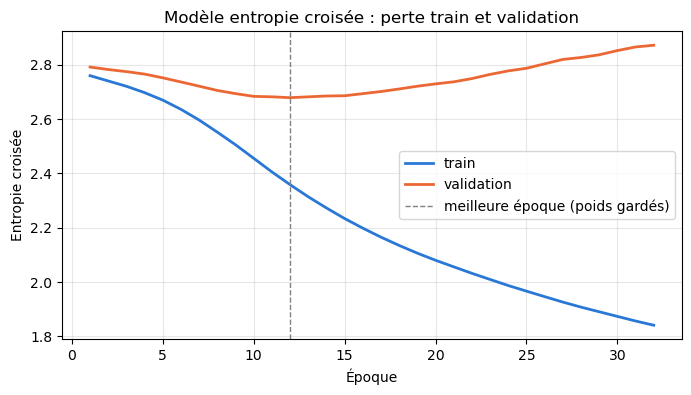

In [10]:
epoques = range(1, len(pertes_train_ce) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epoques, pertes_train_ce, color="#2a78d6", linewidth=2, label="train")
plt.plot(epoques, pertes_val_ce, color="#eb6834", linewidth=2, label="validation")
plt.axvline(meilleure_epoque_ce, color="gray", linestyle="--", linewidth=1, label="meilleure époque (poids gardés)")
plt.xlabel("Époque")
plt.ylabel("Entropie croisée")
plt.title("Modèle entropie croisée : perte train et validation")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Le réseau a-t-il appris quelque chose ?** Une entropie croisée seule ne veut rien dire : il faut la comparer à des prédictions « naïves » qui n'utilisent pas les features :
- l'**équipondéré** : 1/16 sur chaque actif, tous les jours (son entropie croisée vaut toujours $\log 16 \approx 2{,}77$) ;
- la **moyenne des poids oracle du train** : le même portefeuille moyen tous les jours.

Si le réseau ne fait pas mieux que ces deux références, il n'a pas réussi à exploiter les features.
On compare aussi la **concentration** : l'oracle met souvent beaucoup sur peu d'actifs, alors que le réseau prédit une *moyenne* des allocations oracle pour des situations de marché similaires, donc des portefeuilles plus diversifiés. C'est attendu, pas un bug.

In [11]:
model_ce.eval()
with torch.no_grad():
    poids_val_ce = model_ce(X_val_t)  # poids prédits pour les 703 dates de validation

# Un vecteur de 16 poids (sans date) = le même portefeuille appliqué à chaque date
ce_reseau = perte_ce(poids_val_ce, Y_val_t).item()
ce_equipondere = perte_ce(torch.ones(n_actifs) / n_actifs, Y_val_t).item()  # 1/16 partout, chaque jour
ce_moyenne_train = perte_ce(Y_train_t.mean(dim=0), Y_val_t).item()          # poids oracle moyens du train, chaque jour

print("Entropie croisée validation — réseau               :", round(ce_reseau, 4))
print("Entropie croisée validation — équipondéré          :", round(ce_equipondere, 4))
print("Entropie croisée validation — moyenne oracle train :", round(ce_moyenne_train, 4))

# Concentration : poids du plus gros actif, en moyenne sur les dates de validation
print("Plus gros poids moyen — oracle Y :", round(Y_val_t.max(dim=1).values.mean().item(), 3))
print("Plus gros poids moyen — réseau   :", round(poids_val_ce.max(dim=1).values.mean().item(), 3))

Entropie croisée validation — réseau               : 2.6791
Entropie croisée validation — équipondéré          : 2.7726
Entropie croisée validation — moyenne oracle train : 2.6425
Plus gros poids moyen — oracle Y : 0.525
Plus gros poids moyen — réseau   : 0.13


## Étape 4 — Entraînement avec la perte Sharpe

Avec l'entropie croisée, le réseau **imite l'oracle**. Ici, il ne regarde plus du tout `Y` : on note directement **la performance** des portefeuilles qu'il propose, avec ce qui s'est réellement passé ensuite (`R_fwd`).

1. **Rendement excédentaire** de chaque actif = rendement − rendement du cash (le taux sans risque) : ce que l'actif rapporte **en plus** d'un placement sans risque.
2. **Rendement du portefeuille** à une date = $\sum_i \text{poids}_i \times \text{rendement excédentaire}_i$. Exemple : poids (0,5 ; 0,3 ; 0,2) et rendements (10 % ; 2 % ; 0 %) → 5,6 %.
3. **Ratio de Sharpe** sur plusieurs dates = moyenne / écart-type de ces rendements : le gain obtenu par unité de risque.
4. Adam sait seulement faire **baisser** une perte : on prend donc **perte = −Sharpe**. Faire baisser −Sharpe revient à faire monter le Sharpe.

Le Sharpe est calculé sur 63 jours ; on le multiplie par $\sqrt{252/63} = 2$ pour l'**annualiser** (≈ 4 trimestres par an).

In [12]:
i_cash = list(Y.columns).index("CASH")  # numéro de la colonne CASH
ANNUALISATION = np.sqrt(252 / 63)       # = 2 : Sharpe sur 63 jours × √4 trimestres par an ≈ Sharpe annuel
BATCH_SHARPE = 256                      # lots plus grands : un Sharpe calculé sur peu de dates est trop bruité

# Rendements excédentaires : à chaque colonne, on soustrait (sub) le rendement du cash de la même date
R_exc_train_t = tenseur(R_train.sub(R_train["CASH"], axis=0).values)
R_exc_val_t = tenseur(R_val.sub(R_val["CASH"], axis=0).values)

def sharpe(poids, R_exc):
    rendements = (poids * R_exc).sum(dim=1)      # rendement du portefeuille : somme des poids × rendements, une valeur par date
    return rendements.mean() / rendements.std()  # moyenne / écart-type

def perte_sharpe(poids, R_exc):
    return -sharpe(poids, R_exc)  # maximiser le Sharpe = minimiser son opposé

On réutilise **exactement la même fonction `entrainer`** qu'à l'étape 3 : même réseau, mêmes mini-lots, même Adam, même early stopping. Seules deux choses changent :
- la perte : `perte_sharpe` au lieu de `perte_ce`, et la cible : les rendements `R_exc` au lieu des poids oracle `Y` ;
- la taille des lots : 256 dates au lieu de 64.

Comme la perte est −Sharpe, « la perte de validation la plus basse » = « le Sharpe de validation le plus haut » : l'early stopping fonctionne sans rien changer. Le test n'est pas utilisé.

In [13]:
model_sharpe, pertes_train_sharpe, pertes_val_sharpe = entrainer(X_train_t, R_exc_train_t, X_val_t, R_exc_val_t, perte_sharpe, BATCH_SHARPE)

# La perte vaut -Sharpe : on remet le signe et on annualise pour lire des Sharpe
sharpes_train = -ANNUALISATION * np.array(pertes_train_sharpe)
sharpes_val = -ANNUALISATION * np.array(pertes_val_sharpe)

meilleure_epoque_sharpe = int(np.argmax(sharpes_val)) + 1  # argmax : on cherche le Sharpe le plus HAUT
print("Nombre d'époques effectuées :", len(sharpes_val))
print("Meilleure époque :", meilleure_epoque_sharpe, "| Sharpe annualisé de validation :", round(max(sharpes_val), 3))

Nombre d'époques effectuées : 75
Meilleure époque : 55 | Sharpe annualisé de validation : 1.375


**Courbes d'apprentissage.** Cette fois on trace le Sharpe (annualisé), donc **plus haut = mieux**. Si le Sharpe train continue de monter pendant que le Sharpe validation baisse, le réseau apprend le train par cœur : c'est encore de l'overfitting, et l'early stopping garde les poids de la ligne pointillée.

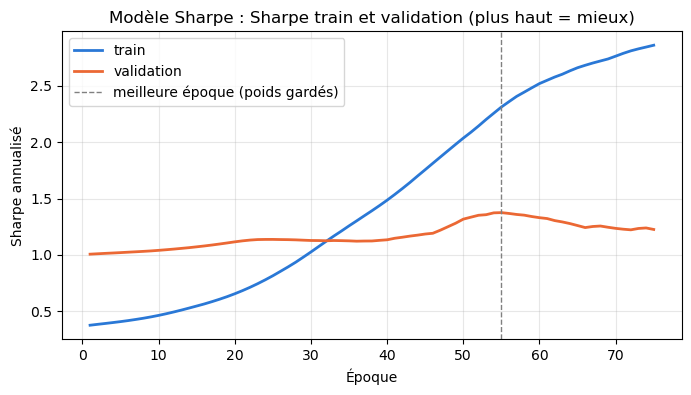

In [14]:
epoques = range(1, len(sharpes_train) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epoques, sharpes_train, color="#2a78d6", linewidth=2, label="train")
plt.plot(epoques, sharpes_val, color="#eb6834", linewidth=2, label="validation")
plt.axvline(meilleure_epoque_sharpe, color="gray", linestyle="--", linewidth=1, label="meilleure époque (poids gardés)")
plt.xlabel("Époque")
plt.ylabel("Sharpe annualisé")
plt.title("Modèle Sharpe : Sharpe train et validation (plus haut = mieux)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Comparaison sur la validation, avec le bon critère : le Sharpe du portefeuille.** On compare les deux MLP à trois références : l'oracle (borne haute impossible à atteindre, car il connaît le futur), l'équipondéré et le portefeuille moyen constant (qui n'utilisent aucune feature). Pour ces deux derniers, on donne à `sharpe` un seul vecteur de 16 poids : torch l'applique automatiquement à chaque date.

**Attention, ces scores de validation sont optimistes pour les MLP** : l'early stopping a choisi l'époque qui marche le mieux sur cette même validation. L'étape 5 corrige ce biais, et le test (étape 6) donnera la mesure honnête.

Remarque sur le cash : le Sharpe ne change pas si l'on met une **part fixe** du portefeuille en cash (exemple : 4 % de rendement pour 8 % de risque donne 0,5 ; avec moitié cash, 2 % pour 4 %, toujours 0,5). La perte Sharpe ne fixe donc pas le *niveau moyen* de cash : le modèle Sharpe peut en détenir beaucoup sans être pénalisé.

In [15]:
model_sharpe.eval()
with torch.no_grad():
    poids_val_sharpe = model_sharpe(X_val_t)

equipondere = torch.ones(n_actifs) / n_actifs  # 16 poids de 1/16
moyenne_train = Y_train_t.mean(dim=0)          # poids oracle moyens sur le train

print("Sharpe annualisé sur la validation")
print("  Oracle Y (connaît le futur) :", round(ANNUALISATION * sharpe(Y_val_t, R_exc_val_t).item(), 2))
print("  Équipondéré                 :", round(ANNUALISATION * sharpe(equipondere, R_exc_val_t).item(), 2))
print("  Portefeuille moyen constant :", round(ANNUALISATION * sharpe(moyenne_train, R_exc_val_t).item(), 2))
print("  MLP - entropie croisée      :", round(ANNUALISATION * sharpe(poids_val_ce, R_exc_val_t).item(), 2))
print("  MLP - perte Sharpe          :", round(ANNUALISATION * sharpe(poids_val_sharpe, R_exc_val_t).item(), 2))

print("\nPart moyenne de cash  - MLP CE :", round(poids_val_ce[:, i_cash].mean().item(), 2),
      "| MLP Sharpe :", round(poids_val_sharpe[:, i_cash].mean().item(), 2))

Sharpe annualisé sur la validation
  Oracle Y (connaît le futur) : 4.26
  Équipondéré                 : 1.01
  Portefeuille moyen constant : 1.16
  MLP - entropie croisée      : 1.19
  MLP - perte Sharpe          : 1.38

Part moyenne de cash  - MLP CE : 0.03 | MLP Sharpe : 0.5


## Étape 5 — Validation croisée chronologique et choix de la configuration

Jusqu'ici, tous nos choix reposent sur **une seule** période de validation (2017–2019, ≈ 11 trimestres) : un réglage peut y paraître bon par pur hasard.
La **validation croisée chronologique** (`TimeSeriesSplit`) découpe train + validation (2006–2019) en **4 plis**. Dans chaque pli, on entraîne sur le passé et on évalue sur la période qui suit, avec un **trou de 63 dates** (`gap=63`, le purging) pour que les labels du train ne débordent pas sur la validation :
```
Pli 1 : [train]            trou [val]
Pli 2 : [train......]           trou [val]
Pli 3 : [train..............]        trou [val]
Pli 4 : [train......................]     trou [val]
```
Les dates ne sont **jamais mélangées** entre train et validation (sinon fuite du futur, voir étape 1). Le test (2020–2025) n'est toujours pas utilisé.

**Configurations comparées** (choisies à l'avance, peu nombreuses pour ne pas surapprendre la validation) :

| Configuration | Ce qu'on teste |
|---|---|
| Base : 64-32, dropout 0,2, 160 features | la référence des étapes 2 à 4 |
| Dropout 0,4 | plus de régularisation aide-t-elle ? |
| Plus petit : 32-16 | moins de paramètres aide-t-il ? |
| Momentum + globales (85 features) | **ablation** : retirer volatilité, drawdown, corrélation des actions |
| Globales seules (10 features) | **ablation** : les informations propres à chaque action servent-elles ? |

In [16]:
dev = train | val  # train + validation (2006-2019) ; le test (2020-2025) reste de côté
X_dev, Y_dev, R_dev = X[dev], Y[dev], R_fwd[dev]
R_exc_dev = R_dev.sub(R_dev["CASH"], axis=0)

# Ensembles de features, construits à partir des noms de colonnes
colonnes_momentum = []
colonnes_globales = []
for c in X.columns:
    if c.startswith("mom_"):
        colonnes_momentum.append(c)
    elif c.endswith("__global") or c.startswith("market__") or c.startswith("macro__"):
        colonnes_globales.append(c)

ensembles_features = {
    "toutes": list(X.columns),
    "momentum + globales": colonnes_momentum + colonnes_globales,
    "globales": colonnes_globales,
}
for nom in ensembles_features:
    print("Ensemble", nom, ":", len(ensembles_features[nom]), "features")

# Configurations comparées : (nom, neurones couche 1, neurones couche 2, dropout, ensemble de features)
configs = [
    ("Base (64-32, dropout 0,2)", 64, 32, 0.2, "toutes"),
    ("Dropout 0,4", 64, 32, 0.4, "toutes"),
    ("Plus petit (32-16)", 32, 16, 0.2, "toutes"),
    ("Momentum + globales", 64, 32, 0.2, "momentum + globales"),
    ("Globales seules", 64, 32, 0.2, "globales"),
]

tscv = TimeSeriesSplit(n_splits=4, gap=63)  # 4 plis, trou de 63 dates entre le train et la validation de chaque pli

# Périodes de chaque pli + Sharpe de l'équipondéré comme repère (certaines périodes sont plus difficiles que d'autres)
pli = 0
for idx_tr, idx_va in tscv.split(X_dev):  # idx_tr, idx_va : numéros des lignes du train et de la validation du pli
    pli = pli + 1
    sharpe_equi = ANNUALISATION * sharpe(equipondere, tenseur(R_exc_dev.values[idx_va])).item()
    print("Pli", pli,
          "| train :", X_dev.index[idx_tr[0]].date(), "->", X_dev.index[idx_tr[-1]].date(),
          "| val :", X_dev.index[idx_va[0]].date(), "->", X_dev.index[idx_va[-1]].date(),
          "| Sharpe équipondéré :", round(sharpe_equi, 2))

Ensemble toutes : 160 features
Ensemble momentum + globales : 85 features
Ensemble globales : 10 features
Pli 1 | train : 2006-01-02 -> 2008-06-19 | val : 2008-09-17 -> 2011-05-30 | Sharpe équipondéré : 0.72
Pli 2 | train : 2006-01-02 -> 2011-02-28 | val : 2011-05-31 -> 2014-02-10 | Sharpe équipondéré : 0.78
Pli 3 | train : 2006-01-02 -> 2013-11-08 | val : 2014-02-11 -> 2017-01-18 | Sharpe équipondéré : 0.67
Pli 4 | train : 2006-01-02 -> 2016-07-25 | val : 2017-01-19 -> 2019-10-02 | Sharpe équipondéré : 0.99


**La boucle de validation croisée.** Pour chaque configuration, et pour chacun des 4 plis :
1. on ne garde que les colonnes de l'ensemble de features choisi ;
2. on coupe le train du pli en deux : les premiers 80 % (moins 63 dates de trou) pour **apprendre**, les 20 % finaux pour l'**early stopping** ;
3. on ajuste le StandardScaler sur la partie apprentissage uniquement ;
4. on entraîne le modèle entropie croisée et le modèle Sharpe avec la fonction `entrainer` ;
5. on note les deux modèles **une seule fois** sur la validation du pli, qu'ils n'ont jamais vue, et on note aussi l'équipondéré comme repère.

Pourquoi ne pas faire l'early stopping directement sur la validation du pli ? Parce qu'on garderait la meilleure époque *sur cette validation*, puis on noterait le modèle *sur cette même validation* : c'est comme garder la meilleure note après avoir passé 70 fois le même examen, le score serait gonflé par la chance.

5 configurations × 4 plis × 2 modèles = 40 entraînements.

In [17]:
lignes = []
for nom, n1, n2, dropout, features in configs:
    X_cfg = X_dev[ensembles_features[features]].values  # seulement les colonnes de cet ensemble de features
    pli = 0
    for idx_tr, idx_va in tscv.split(X_cfg):
        pli = pli + 1
        # Les 20 % finaux du train du pli servent à l'early stopping (après un trou de 63 dates) ;
        # la validation du pli n'est utilisée qu'une seule fois, à la fin, pour la note
        coupe = int(len(idx_tr) * 0.8)
        idx_app = idx_tr[:coupe - 63]  # apprentissage
        idx_es = idx_tr[coupe:]        # early stopping

        # Scaler ajusté sur la partie apprentissage uniquement (pas de fuite du futur)
        scaler_pli = StandardScaler()
        scaler_pli.fit(X_cfg[idx_app])
        X_app = tenseur(scaler_pli.transform(X_cfg[idx_app]))
        X_es = tenseur(scaler_pli.transform(X_cfg[idx_es]))
        X_va = tenseur(scaler_pli.transform(X_cfg[idx_va]))

        # Les deux modèles, avec la même fonction entrainer (seules la perte et la cible changent)
        m_ce, courbe_train, courbe_es = entrainer(X_app, tenseur(Y_dev.values[idx_app]), X_es, tenseur(Y_dev.values[idx_es]),
                                                  perte_ce, BATCH_CE, n1, n2, dropout)
        m_sharpe, courbe_train, courbe_es = entrainer(X_app, tenseur(R_exc_dev.values[idx_app]), X_es, tenseur(R_exc_dev.values[idx_es]),
                                                      perte_sharpe, BATCH_SHARPE, n1, n2, dropout)

        # Note finale sur la validation du pli, regardée une seule fois
        Y_va = tenseur(Y_dev.values[idx_va])
        R_va = tenseur(R_exc_dev.values[idx_va])
        with torch.no_grad():
            lignes.append([nom, pli,
                           perte_ce(m_ce(X_va), Y_va).item(),
                           ANNUALISATION * sharpe(m_ce(X_va), R_va).item(),
                           ANNUALISATION * sharpe(m_sharpe(X_va), R_va).item(),
                           ANNUALISATION * sharpe(equipondere, R_va).item()])
    print("Terminé :", nom)

resultats_cv = pd.DataFrame(lignes, columns=["Configuration", "Pli", "Entropie croisée (modèle CE)", "Sharpe (modèle CE)",
                                             "Sharpe (modèle Sharpe)", "Sharpe équipondéré"])

Terminé : Base (64-32, dropout 0,2)
Terminé : Dropout 0,4
Terminé : Plus petit (32-16)
Terminé : Momentum + globales
Terminé : Globales seules


**Tableau des résultats : moyenne sur les 4 plis.** Chaque modèle est jugé sur son propre objectif : l'entropie croisée la plus basse pour le modèle entropie croisée, le Sharpe le plus haut pour le modèle Sharpe. On affiche aussi le Sharpe du portefeuille du modèle entropie croisée, pour comparer les deux sur le même critère.
L'**écart-type entre les plis** mesure le bruit : si deux configurations diffèrent de moins que cet écart-type, la différence n'est pas fiable et pourrait venir du hasard.

In [18]:
colonnes_scores = ["Entropie croisée (modèle CE)", "Sharpe (modèle CE)", "Sharpe (modèle Sharpe)", "Sharpe équipondéré"]
tableau_cv = resultats_cv.groupby("Configuration", sort=False)[colonnes_scores].mean()  # moyenne sur les 4 plis
tableau_cv["Écart-type Sharpe (modèle Sharpe)"] = resultats_cv.groupby("Configuration", sort=False)["Sharpe (modèle Sharpe)"].std()
print(tableau_cv.round(4))

config_ce = tableau_cv["Entropie croisée (modèle CE)"].idxmin()  # entropie croisée la plus basse
config_sharpe = tableau_cv["Sharpe (modèle Sharpe)"].idxmax()    # Sharpe le plus haut
print("\nConfiguration retenue pour le modèle CE     :", config_ce)
print("Configuration retenue pour le modèle Sharpe :", config_sharpe)

                           Entropie croisée (modèle CE)  Sharpe (modèle CE)  \
Configuration                                                                 
Base (64-32, dropout 0,2)                        2.8265              0.8011   
Dropout 0,4                                      2.8222              0.8020   
Plus petit (32-16)                               2.8488              0.8772   
Momentum + globales                              2.7822              0.8261   
Globales seules                                  2.8755              0.7951   

                           Sharpe (modèle Sharpe)  Sharpe équipondéré  \
Configuration                                                           
Base (64-32, dropout 0,2)                  0.7859              0.7889   
Dropout 0,4                                0.7601              0.7889   
Plus petit (32-16)                         0.8306              0.7889   
Momentum + globales                        0.7919              0.7889   
Globales

## Étape 6 — Modèles finaux, prédictions sur le test et export

**Configuration retenue : 32-16 neurones, dropout 0,2, toutes les features**, pour les deux modèles. Avec la validation croisée honnête, c'est la configuration qui donne le meilleur Sharpe pour le modèle entropie croisée comme pour le modèle Sharpe ; c'est aussi la plus simple (moins de paramètres). Garder la même architecture pour les deux modèles rend leur comparaison plus propre : seule la perte change.

On réentraîne les deux modèles sur le train, avec early stopping sur la validation, exactement comme aux étapes 3 et 4.

In [19]:
N1_FINAL, N2_FINAL, DROPOUT_FINAL = 32, 16, 0.2  # configuration retenue par la validation croisée

modele_ce_final, courbe_train, pertes_val_ce_final = entrainer(X_train_t, Y_train_t, X_val_t, Y_val_t,
                                                               perte_ce, BATCH_CE, N1_FINAL, N2_FINAL, DROPOUT_FINAL)
modele_sharpe_final, courbe_train, pertes_val_sharpe_final = entrainer(X_train_t, R_exc_train_t, X_val_t, R_exc_val_t,
                                                                       perte_sharpe, BATCH_SHARPE, N1_FINAL, N2_FINAL, DROPOUT_FINAL)

print("Modèle entropie croisée : meilleure époque", int(np.argmin(pertes_val_ce_final)) + 1)
print("Modèle Sharpe           : meilleure époque", int(np.argmin(pertes_val_sharpe_final)) + 1)

Modèle entropie croisée : meilleure époque 4
Modèle Sharpe           : meilleure époque 73


**Évaluation sur le test (2020–2025), faite une seule fois.** C'est la seule mesure vraiment honnête : ni l'entraînement, ni l'early stopping, ni le choix de la configuration n'ont utilisé ces dates.
On calcule l'entropie croisée (écart à l'oracle) et le Sharpe annualisé des portefeuilles, comparés aux mêmes références qu'avant.

In [20]:
Y_test_t = tenseur(Y[test].values)
R_test = R_fwd[test]
R_exc_test_t = tenseur(R_test.sub(R_test["CASH"], axis=0).values)

with torch.no_grad():
    poids_test_ce = modele_ce_final(X_test_t)
    poids_test_sharpe = modele_sharpe_final(X_test_t)

print("Entropie croisée sur le test")
print("  MLP entropie croisée        :", round(perte_ce(poids_test_ce, Y_test_t).item(), 4))
print("  Équipondéré                 :", round(perte_ce(equipondere, Y_test_t).item(), 4))
print("  Portefeuille moyen constant :", round(perte_ce(moyenne_train, Y_test_t).item(), 4))

print("\nSharpe annualisé sur le test")
print("  Oracle Y (connaît le futur) :", round(ANNUALISATION * sharpe(Y_test_t, R_exc_test_t).item(), 2))
print("  Équipondéré                 :", round(ANNUALISATION * sharpe(equipondere, R_exc_test_t).item(), 2))
print("  Portefeuille moyen constant :", round(ANNUALISATION * sharpe(moyenne_train, R_exc_test_t).item(), 2))
print("  MLP - entropie croisée      :", round(ANNUALISATION * sharpe(poids_test_ce, R_exc_test_t).item(), 2))
print("  MLP - perte Sharpe          :", round(ANNUALISATION * sharpe(poids_test_sharpe, R_exc_test_t).item(), 2))

Entropie croisée sur le test
  MLP entropie croisée        : 2.7883
  Équipondéré                 : 2.7726
  Portefeuille moyen constant : 2.789

Sharpe annualisé sur le test
  Oracle Y (connaît le futur) : 4.72
  Équipondéré                 : 0.78
  Portefeuille moyen constant : 0.71
  MLP - entropie croisée      : 0.76
  MLP - perte Sharpe          : 0.72


**Vérifications sur les poids prédits.** Les poids doivent sommer à 1 (garanti par le softmax). On mesure aussi le **turnover** : la part du portefeuille qui change d'une date à la suivante, $\frac{1}{2}\sum_i |w_{i,t} - w_{i,t-1}|$. Un turnover faible veut dire des portefeuilles stables, donc peu de frais de transaction.

In [21]:
def turnover_moyen(poids):
    # moitié de la somme des |changements de poids| d'une date à la suivante, en moyenne sur les dates
    return ((poids[1:] - poids[:-1]).abs().sum(dim=1) / 2).mean().item()

print("Somme des poids : min =", round(poids_test_ce.sum(dim=1).min().item(), 4), "| max =", round(poids_test_ce.sum(dim=1).max().item(), 4))
print("Turnover moyen d'un jour au suivant — CE :", round(turnover_moyen(poids_test_ce), 4),
      "| Sharpe :", round(turnover_moyen(poids_test_sharpe), 4), "| oracle :", round(turnover_moyen(Y_test_t), 4))
print("Part moyenne de cash — CE :", round(poids_test_ce[:, i_cash].mean().item(), 2),
      "| Sharpe :", round(poids_test_sharpe[:, i_cash].mean().item(), 2))
print("Plus gros poids moyen — CE :", round(poids_test_ce.max(dim=1).values.mean().item(), 3),
      "| oracle :", round(Y_test_t.max(dim=1).values.mean().item(), 3))

Somme des poids : min = 1.0 | max = 1.0
Turnover moyen d'un jour au suivant — CE : 0.0111 | Sharpe : 0.0489 | oracle : 0.1143
Part moyenne de cash — CE : 0.06 | Sharpe : 0.24
Plus gros poids moyen — CE : 0.087 | oracle : 0.483


**Export pour le groupe.** On sauvegarde les poids prédits sur le test dans `outputs/` : une ligne par date du test, 16 colonnes (mêmes noms que `Y.csv`). Le reste du groupe s'en sert pour le backtest complet et la comparaison avec les méthodes classiques.

In [22]:
os.makedirs("outputs", exist_ok=True)  # crée le dossier s'il n'existe pas encore

# Index = dates du test, 16 colonnes = mêmes colonnes que Y.csv
pred_ce = pd.DataFrame(poids_test_ce.numpy(), index=X_test.index, columns=Y.columns)
pred_sharpe = pd.DataFrame(poids_test_sharpe.numpy(), index=X_test.index, columns=Y.columns)
pred_ce.to_csv("outputs/pred_mlp_ce.csv")
pred_sharpe.to_csv("outputs/pred_mlp_sharpe.csv")

print("Fichiers écrits :", pred_ce.shape, "et", pred_sharpe.shape, "(dates × actifs)")
print(pred_ce.head(3).round(3))

Fichiers écrits : (1474, 16) et (1474, 16) (dates × actifs)
            MC.PA  OR.PA  BN.PA  TTE.PA  VIE.PA  SAN.PA  BNP.PA  GLE.PA  \
date                                                                      
2020-01-02  0.043  0.060  0.057   0.061   0.069   0.067   0.055   0.052   
2020-01-03  0.044  0.061  0.057   0.061   0.070   0.066   0.056   0.054   
2020-01-06  0.043  0.059  0.058   0.061   0.070   0.067   0.055   0.053   

            AIR.PA  SU.PA  DG.PA  SGO.PA  AI.PA  ORA.PA  CAP.PA   CASH  
date                                                                    
2020-01-02   0.092  0.046  0.057   0.042  0.087   0.054   0.083  0.073  
2020-01-03   0.091  0.046  0.057   0.044  0.086   0.054   0.082  0.072  
2020-01-06   0.092  0.046  0.056   0.042  0.087   0.054   0.085  0.073  
